## Basic agent ## 


Set Up code

In [265]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Go from src/ax_agent to project root
env_path = Path.cwd().parents[1] / ".env"

print("Env file:", env_path)
print("File exists:", env_path.exists())

load_dotenv(dotenv_path=env_path, override=True)

SUPABASE_DB_URL = os.getenv("SUPABASE_DB_URL")
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

print("Supabase URL loaded:", bool(SUPABASE_DB_URL))
print("OpenAI key loaded:", bool(OPENAI_API_KEY))
print(
    "Correct URL prefix:",
    SUPABASE_DB_URL.startswith("postgresql://")
    if SUPABASE_DB_URL else False
)




Env file: d:\agent_db\.env
File exists: True
Supabase URL loaded: True
OpenAI key loaded: True
Correct URL prefix: True


In [266]:
from langchain_openai import ChatOpenAI

llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)
llm_openai.invoke("Hii").content



'Hi! How can I help you today?'

In [267]:

from typing import TypedDict, Literal

class graph_schema(TypedDict):
    question: str
    summery_question: str
    answer: str
    feedback: str
    is_correct: bool
    retry_count: int

    selected_tool: Literal[
        "duckduckgo",
        "supabase_sql",
        "none"
    ]

    sql_query: str
    sql_result: str

    # New SQL fields
    sql_executed: bool
    sql_error: str
    sql_retry_count: int


In [268]:
from pydantic import BaseModel, Field

class evaluation_schema(BaseModel):
    is_correct: bool = Field(
        description="Whether the answer correctly and sufficiently answers the question."
    )
    feedback: str = Field(
        description="Explain what is missing or incorrect. Empty string if the answer is satisfactory."
    )

evaluator_llm = llm_openai.with_structured_output(evaluation_schema)

In [269]:
import os
import re

import psycopg
from psycopg.rows import dict_row
from dotenv import load_dotenv
from langchain_core.tools import tool

load_dotenv()

SUPABASE_DB_URL = os.getenv("SUPABASE_DB_URL")

@tool
def supabase_sql_tool(query: str) -> str:
    """
    Execute read-only SELECT queries on Supabase PostgreSQL.
    Used to retrieve records from database tables.
    """

    cleaned_query = query.strip().rstrip(";")

    # Allow SELECT or WITH queries only
    if not re.match(r"^(SELECT|WITH)\b", cleaned_query, re.IGNORECASE):
        return "Error: Only SELECT queries are allowed."

    # Prevent multiple SQL statements
    if ";" in cleaned_query:
        return "Error: Multiple SQL statements are not allowed."

    try:
        with psycopg.connect(
            SUPABASE_DB_URL,
            row_factory=dict_row
        ) as connection:

            with connection.cursor() as cursor:

                # Enforce read-only transaction
                cursor.execute("SET TRANSACTION READ ONLY")

                cursor.execute(cleaned_query)

                rows = cursor.fetchmany(50)

                if not rows:
                    return "No records found."

                return str(rows)

    except Exception as e:
        return f"Database error: {str(e)}"

## Genrate SQL Query 

In [270]:

def execute_sql(state: graph_schema) -> dict:

    print("Supabase SQL Tool Called!")

    verification = verify_sql_execution(state["sql_query"])

    if not verification["is_valid"]:

        print("SQL Execution Failed:", verification["error"])

        return {
            "sql_result": "",
            "sql_error": verification["error"],
            "sql_executed": False,
            "sql_retry_count": state.get("sql_retry_count", 0) + 1
        }

    print("SQL Execution Successful")
    print("Rows returned:", verification["row_count"])

    return {
        "sql_result": str(verification["data"]),
        "sql_error": "",
        "sql_executed": True
    }


In [271]:
from langchain_core.tools import tool
import psycopg
from psycopg.rows import dict_row

@tool
def inspect_database_schema() -> str:
    """
    Inspect database tables and their columns.
    Use this before generating SQL queries.
    """

    try:
        with psycopg.connect(
            SUPABASE_DB_URL,
            row_factory=dict_row
        ) as connection:

            with connection.cursor() as cursor:

                cursor.execute("""
                    SELECT
                        table_name,
                        column_name,
                        data_type
                    FROM information_schema.columns
                    WHERE table_schema = 'public'
                    ORDER BY table_name, ordinal_position;
                """)

                rows = cursor.fetchall()

                if not rows:
                    return "No tables found."

                schema = {}

                for row in rows:
                    table = row["table_name"]

                    if table not in schema:
                        schema[table] = []

                    schema[table].append(
                        f'{row["column_name"]} ({row["data_type"]})'
                    )

                result = ""

                for table, columns in schema.items():
                    result += f"\nTable: {table}\n"
                    result += "Columns: " + ", ".join(columns) + "\n"

                return result

    except Exception as e:
        return f"Schema inspection error: {str(e)}"

In [272]:
schema_result = inspect_database_schema.invoke({})

print(schema_result)


Table: ai_test_results
Columns: result_id (integer), ai_test_id (integer), student_id (integer), marks_obtained (integer), total_marks (integer), student_answers (jsonb), submitted_at (timestamp without time zone)

Table: ai_tests
Columns: ai_test_id (integer), faculty_id (integer), batch_id (integer), standard (character varying), subject (character varying), topic (character varying), exam_type (character varying), no_of_questions (integer), duration_minutes (integer), questions_data (jsonb), created_at (timestamp without time zone), status (character varying)

Table: announcements
Columns: announcement_id (integer), owner_id (integer), batch_id (integer), title (character varying), body (text), created_at (timestamp without time zone)

Table: attempt_answers
Columns: answer_id (integer), attempt_id (integer), question_id (integer), selected_option_id (integer), written_answer (text), marks_awarded (integer)

Table: attendance
Columns: attendance_id (integer), lecture_id (integer), 

In [273]:

def generate_sql(state: graph_schema) -> dict:

    schema_result = inspect_database_schema.invoke({})

    prompt = ChatPromptTemplate.from_messages([
        ("system", """
You are an expert PostgreSQL query generator.

Generate accurate SQL using the actual database schema.

Rules:
1. Generate only SELECT or WITH ... SELECT queries.
2. Never generate INSERT, UPDATE, DELETE, DROP, ALTER or TRUNCATE.
3. Never generate multiple SQL statements.
4. Never invent tables, columns, or IDs.
5. Use only tables and columns in the schema.
6. Use users.user_id = students.user_id for student names.
7. Use students.pending_fees > 0 for pending fee queries.
8. Resolve institute names using class_owners.
9. Do not assume owner_id is always populated.
10. For count questions, calculate the count using SQL.
11. Avoid duplicate student records.
12. Return only executable PostgreSQL SQL.

If the previous query failed, correct it using the
database error and previous SQL query.

Database Schema:
{schema}
        """),

        ("human", """
Original Question:
{question}

Question Summary:
{summary}

Previous SQL Query:
{previous_query}

Previous SQL Error:
{sql_error}

Generate the corrected SQL query.
        """)
    ])

    response = (prompt | llm_openai).invoke({
        "question": state["question"],
        "summary": state.get("summery_question", ""),
        "schema": schema_result,
        "previous_query": state.get("sql_query", ""),
        "sql_error": state.get("sql_error", "")
    })

    sql_query = response.content.strip()

    print("Generated SQL:", sql_query)

    return {
        "sql_query": sql_query,
        "sql_result": "",
        "sql_error": "",
        "sql_executed": False
    }


In [274]:
import re

def validate_sql_query(query: str) -> tuple[bool, str]:

    query = query.strip()

    # Check empty query
    if not query:
        return False, "SQL query is empty."

    # Only SELECT or WITH queries
    if not re.match(r"^(SELECT|WITH)\b", query, re.IGNORECASE):
        return False, "Only SELECT queries are allowed."

    # Reject multiple SQL statements
    if ";" in query.rstrip(";"):
        return False, "Multiple SQL statements are not allowed."

    # Reject dangerous SQL commands
    forbidden = r"\b(INSERT|UPDATE|DELETE|DROP|ALTER|TRUNCATE|CREATE|GRANT|REVOKE)\b"

    if re.search(forbidden, query, re.IGNORECASE):
        return False, "Query contains a forbidden SQL operation."

    return True, "SQL query passed basic validation."

In [275]:
import psycopg
from psycopg.rows import dict_row

def verify_sql_execution(query: str):

    is_valid, message = validate_sql_query(query)

    if not is_valid:
        return {
            "is_valid": False,
            "error": message,
            "data": None
        }

    try:
        with psycopg.connect(
            SUPABASE_DB_URL,
            row_factory=dict_row
        ) as conn:

            with conn.cursor() as cursor:

                cursor.execute("SET TRANSACTION READ ONLY")
                cursor.execute("SET LOCAL statement_timeout = '10s'")

                cursor.execute(query)

                rows = cursor.fetchmany(50)

                return {
                    "is_valid": True,
                    "error": None,
                    "data": rows,
                    "row_count": len(rows)
                }

    except Exception as e:
        return {
            "is_valid": False,
            "error": str(e),
            "data": None
        }

In [276]:
def answer_from_database(state: graph_schema) -> dict:

    prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are a helpful Database Assistant.

            Answer the user's question using the database results.

            Rules:
            1. Give a direct answer.
            2. Keep the answer short but informative.
            3. Use bullet points when useful.
            4. Do not invent database records.
            5. If no records are found, clearly say so.
        """),
        ("human", """
            User Question: {question}

            SQL Query: {sql_query}

            Database Results: {sql_result}

            Give the final answer.
        """)
    ])

    response = (prompt | llm_openai).invoke({
        "question": state["question"],
        "sql_query": state["sql_query"],
        "sql_result": state["sql_result"]
    })

    return {
        "answer": response.content
    }

## Create a question Fixer ## 

In [277]:
from langchain_core.prompts import ChatPromptTemplate

def fix_question(state: graph_schema) -> graph_schema:

    user_question = state["question"]

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", "You are a question corrector. Correct the user's grammar and spelling without changing the meaning."),
        ("human", "{user_question}")
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "user_question": user_question
    })

    return {
        "question": response.content
    }



## Question Summery ##

In [278]:
from langchain_core.prompts import ChatPromptTemplate

def summery_question(state: graph_schema) -> graph_schema:

    user_question = state["question"]

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", """
                You are a Question Summarization Agent.
                Understand the user's question and summarize it in one short sentence.
                Preserve the original intent and important details.
                Do not answer the question.
                Return only the summarized question.
        """),
        ("human", "{user_question}")
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "user_question": user_question
    })

    return {
        "summery_question": response.content
    }



## Question Answer LLM ##

In [279]:
from langchain_core.prompts import ChatPromptTemplate

def answer_question(state: graph_schema) -> dict:

    user_question = state["question"]
    question_summary = state["summery_question"]

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are a helpful AI Question Answering Agent.

            Your task is to:
            1. Understand the user's original question.
            2. Use the question summary to understand the main intent.
            3. Provide an accurate, relevant, and easy-to-understand answer.
            4. Explain concepts with examples whenever helpful.
            5. If you don't know the answer, clearly say so.
            6. Do not simply repeat or summarize the question.
        """),
        ("human", """
            Original Question: {user_question}

            Question Summary: {question_summary}

            Feedback: {feedback}

            Please answer the original question.
        """)
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "user_question": user_question,
        "question_summary": question_summary,
        "feedback": state["feedback"]
    })

    return {
        "answer": response.content
    }



create tool

In [280]:
from langchain_community.tools import DuckDuckGoSearchRun

duckduckgo_search = DuckDuckGoSearchRun()

# Test the tool
result = duckduckgo_search.invoke("Latest AI news in India")

print(result)

artificial intelligence in india Latest Breaking News, Pictures, Videos, and Special Reports from The Economic Times. artificial intelligence in india Blogs, Comments and Archive News on Economictimes.com Artificial Intelligence: Read latest updates on AI like Google AI, ChatGPT, Google Lamda, Bard chatbot and more along with latest news as AI technology advances and makes new progress. All get detailed articles on AI related queries like what is AI, types of artificial intelligence, its applications and future. india artificial intelligence news Latest Breaking News, Pictures, Videos, and Special Reports from The Economic Times. india artificial intelligence news Blogs, Comments and Archive News on Economictimes.com Artificial Intelligence (AI) News: Read more about the latest artificial intelligence news, and research, including web stories & videos at Gadgets News Artificial Intelligence Latest breaking news, pictures, photos and Video News. Find Artificial Intelligence news headlin

## answer_from_search

In [281]:
def answer_from_search(state: graph_schema) -> dict:

    print("DuckDuckGo Search Tool Called!")

    search_result = duckduckgo_search.invoke(state["question"])

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are an expert AI Research Assistant.

            Your task is to create a short but informative answer
            using the provided search results.

            Follow these rules:

            1. Start with a direct answer to the user's question.
            2. Use simple and easy-to-understand language.
            3. Keep the answer concise but informative.
            4. Include the most important facts and details.
            5. Use bullet points for multiple important details.
            6. Include dates, numbers, and examples when relevant.
            7. Avoid unnecessary introductions and repeated information.
            8. Do not make up information.
            9. If search results do not contain enough information,
               clearly mention that.

            Response format:
            - Direct answer
            - Important details (if needed)
            - Short conclusion (if needed)

            Keep the response around 100-150 words.
        """),
        ("human", """
            User Question:
            {question}

            Search Results:
            {search_result}

            Generate the final answer.
        """)
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "question": state["question"],
        "search_result": search_result
    })

    return {
        "answer": response.content
    }

In [282]:
from pydantic import BaseModel, Field
from typing import Literal

class tool_decision(BaseModel):

    selected_tool: Literal[
        "duckduckgo",
        "supabase_sql",
        "none"
    ] = Field(
        description="Select the appropriate tool for the user's question."
    )


tool_decision_llm = llm_openai.with_structured_output(tool_decision)

Create a desaition node


In [283]:
def select_tool(state: graph_schema) -> dict:

    prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are an AI Tool Selection Agent.

            Select the correct tool based on the user's question.

            Available tools:

            1. duckduckgo:
               Use for latest news, current information,
               live updates and internet research.

            2. supabase_sql:
               Use when the user asks about database records,
               students, payments, users or stored information.

            3. none:
               Use for general knowledge questions that
               do not require external tools.

            Select only one tool.
        """),
        ("human", """
            Original Question: {question}
            Question Summary: {summary}
        """)
    ])

    response = (prompt | tool_decision_llm).invoke({
        "question": state["question"],
        "summary": state["summery_question"]
    })

    print("Selected Tool:", response.selected_tool)

    return {
        "selected_tool": response.selected_tool
    }

In [284]:
def route_tool(state: graph_schema) -> str:

    return state["selected_tool"]

## Evaluate Answer ##


In [285]:
def evaluate_answer(state: graph_schema) -> dict:

    evaluation_prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are an Answer Evaluation Agent.

            Evaluate the answer based on the original question.

            Check:
            1. Is the answer factually correct?
            2. Does it answer the actual question?
            3. Is important information missing?
            4. Is the answer clear and relevant?

            If the answer is correct and sufficient:
            - Set is_correct to True.
            - Set feedback to an empty string.

            Otherwise:
            - Set is_correct to False.
            - Provide specific feedback to improve the answer.
        """),
        ("human", """
            Question: {question}
            Answer: {answer}
        """)
    ])

    chain = evaluation_prompt | evaluator_llm

    response = chain.invoke({
        "question": state["question"],
        "answer": state["answer"]
    })

    return {
        "is_correct": response.is_correct,
        "feedback": response.feedback,
        "retry_count": state["retry_count"] + 1
    }

In [286]:
def check_answer(state: graph_schema) -> str:

    if state["is_correct"]:
        return "end"

    if state["retry_count"] >= 3:
        return "end"

    return "retry"

In [287]:
def route_search(state: graph_schema) -> str:

    if state["need_search"]:
        return "search"

    return "llm"

In [288]:
def route_after_sql(state: graph_schema) -> str:

    if state.get("sql_executed", False):
        return "success"

    if state.get("sql_retry_count", 0) < 3:
        return "retry"

    return "failed"

In [289]:
def sql_failed(state: graph_schema) -> dict:

    return {
        "answer": (
            "I could not retrieve the requested database information "
            "after three SQL attempts. "
            f"Last database error: {state.get('sql_error', 'Unknown error')}"
        )
    }

Connect the state

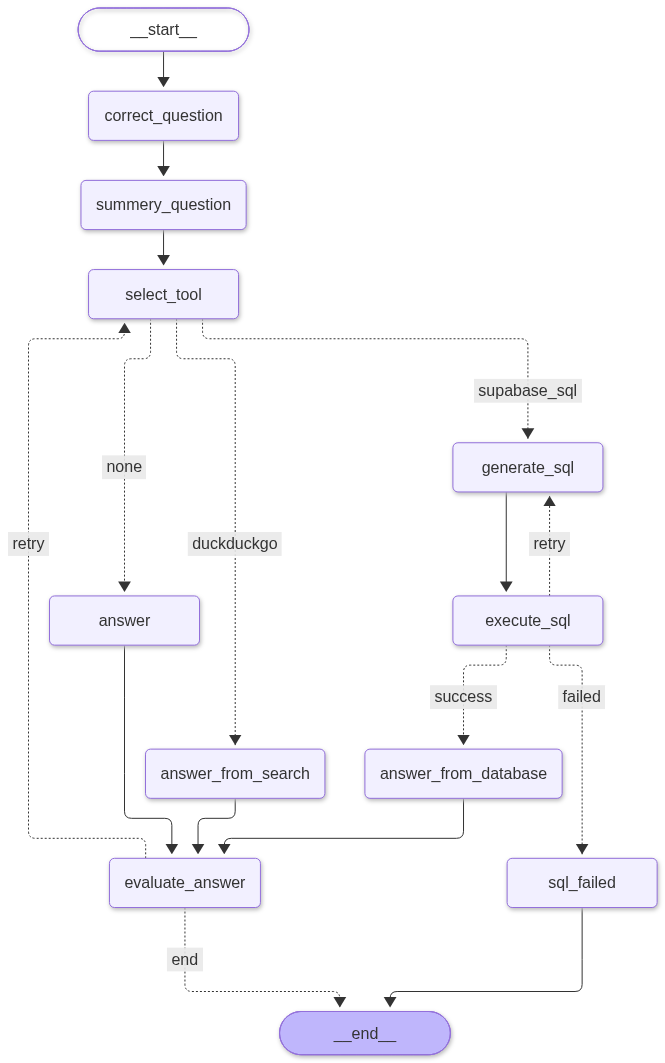

In [290]:

from langgraph.graph import StateGraph, START, END

# Step 1: Create StateGraph
graph = StateGraph(graph_schema)


# Step 2: Register all nodes

# Question processing
graph.add_node("correct_question", fix_question)
graph.add_node("summery_question", summery_question)

# Tool selection
graph.add_node("select_tool", select_tool)

# Normal LLM
graph.add_node("answer", answer_question)

# DuckDuckGo
graph.add_node("answer_from_search", answer_from_search)

# Supabase SQL
graph.add_node("generate_sql", generate_sql)
graph.add_node("execute_sql", execute_sql)
graph.add_node("answer_from_database", answer_from_database)

# SQL failure
graph.add_node("sql_failed", sql_failed)

# Answer evaluation
graph.add_node("evaluate_answer", evaluate_answer)


# Step 3: Normal workflow

graph.add_edge(START, "correct_question")

graph.add_edge(
    "correct_question",
    "summery_question"
)

graph.add_edge(
    "summery_question",
    "select_tool"
)


# Step 4: Tool selection routing

graph.add_conditional_edges(
    "select_tool",
    route_tool,
    {
        "duckduckgo": "answer_from_search",
        "supabase_sql": "generate_sql",
        "none": "answer"
    }
)


# Step 5: SQL workflow

graph.add_edge(
    "generate_sql",
    "execute_sql"
)

graph.add_conditional_edges(
    "execute_sql",
    route_after_sql,
    {
        "retry": "generate_sql",
        "success": "answer_from_database",
        "failed": "sql_failed"
    }
)


# Step 6: Connect answer nodes to evaluator

graph.add_edge(
    "answer",
    "evaluate_answer"
)

graph.add_edge(
    "answer_from_search",
    "evaluate_answer"
)

graph.add_edge(
    "answer_from_database",
    "evaluate_answer"
)


# Step 7: SQL failure goes directly to END

graph.add_edge(
    "sql_failed",
    END
)


# Step 8: Answer evaluation routing

graph.add_conditional_edges(
    "evaluate_answer",
    check_answer,
    {
        "retry": "select_tool",
        "end": END
    }
)


# Step 9: Compile graph

final_result = graph.compile()


# Step 10: Visualize graph

from IPython.display import Image, display

display(
    Image(final_result.get_graph().draw_mermaid_png())
)


In [291]:

result = final_result.invoke({

    "question": """
    Show me students in AK Academy who have pending fees.
    Give me the count, student names and mobile numbers.
    """,

    "summery_question": "",
    "answer": "",
    "feedback": "",

    "is_correct": False,
    "retry_count": 0,

    "selected_tool": "none",

    "sql_query": "",
    "sql_result": "",

    "sql_executed": False,
    "sql_error": "",
    "sql_retry_count": 0
})


print("Corrected Question:", result["question"])
print("Question Summary:", result["summery_question"])
print("Selected Tool:", result["selected_tool"])
print("Generated SQL:", result["sql_query"])
print("Database Result:", result["sql_result"])
print("Final Answer:", result["answer"])
print("Is Correct:", result["is_correct"])
print("Feedback:", result["feedback"])
print("SQL Retry Count:", result["sql_retry_count"])
print("Answer Retry Count:", result["retry_count"])



Selected Tool: supabase_sql
Generated SQL: WITH ak_students AS (
  SELECT DISTINCT s.student_id,
         u.full_name,
         COALESCE(u.mobile, spe.mobile) AS mobile
  FROM students s
  JOIN users u ON u.user_id = s.user_id
  LEFT JOIN student_profile_extras spe ON spe.student_id = s.student_id
  JOIN class_owners co
    ON (co.owner_id = s.owner_id OR (co.institute_id IS NOT NULL AND co.institute_id = s.institute_id))
  WHERE co.institute_name = 'AK Academy'
    AND s.pending_fees > 0
)
SELECT
  (SELECT COUNT(*) FROM ak_students) AS total_pending_count,
  student_id,
  full_name AS student_name,
  mobile
FROM ak_students
ORDER BY full_name;
Supabase SQL Tool Called!
SQL Execution Successful
Rows returned: 0
Corrected Question: Show me the students in AK Academy who have pending fees. Give me the count, student names, and mobile numbers.
Question Summary: Provide the count, names, and mobile numbers of students at AK Academy who have pending fees.
Selected Tool: supabase_sql
Generat